In [ ]:
import os
import glob
import pandas as pd

# 1. 파일 불러오기
target_file = 'lenta_korea_2025-07-11_2025-12-31.xlsx'

if os.path.exists(target_file):
    file_path = target_file
else:
    xlsx_files = glob.glob("*.xlsx")
    file_path = xlsx_files[0] if xlsx_files else target_file

df = pd.read_excel(file_path, sheet_name='기사(본문)')
print(f"📁 원본 기사 불러오기 완료: 총 {len(df)}건")

# 공통 노이즈 키워드 및 휴전 시나리오 단어 정의
soviet_noise_keywords = [
    'олимпиада-1980', 'черенков', 'гомельский', 'курильской десантной',
    'юрия соколова', 'пржевальский', 'разгромил японию'
]
scenario_keywords = ['сценари', 'модел']

# ---------------------------------------------------------
# 2. 남한 중심 기사 필터링 함수 (팀원 로직과 100% 동일)
# ---------------------------------------------------------
def is_south_korea_article(row):
    title = str(row['제목'])
    text = str(row['본문'])
    south_cnt = row['남한 언급 수']
    north_cnt = row['북한 언급 수']
    category = str(row['분류'])

    # 남한 중심 및 언급 수 조건
    is_south_main = (category == '남한') or (south_cnt > north_cnt)
    if not (is_south_main and south_cnt > 0):
        return False

    # 소련/역사 노이즈 제거
    title_lower = title.lower()
    if any(kw in title_lower for kw in soviet_noise_keywords):
        return False

    # 노이즈 및 휴전 시나리오 기사 제거
    if south_cnt == 0 and north_cnt == 0:
        has_scenario = any(kw in text.lower() or kw in title_lower for kw in scenario_keywords)
        if has_scenario:
            return False

    # 필수 키워드 체크 (코리아 / 서울 / 남한)
    korea_keywords = ['коре', 'сеул', 'южн']
    if not any(kw in text.lower() for kw in korea_keywords):
        return False

    return True

# ---------------------------------------------------------
# 3. 북한 중심 기사 필터링 함수 (팀원 로직과 대칭)
# ---------------------------------------------------------
def is_north_korea_article(row):
    title = str(row['제목'])
    text = str(row['본문'])
    south_cnt = row['남한 언급 수']
    north_cnt = row['북한 언급 수']
    category = str(row['분류'])

    # 북한 중심 및 언급 수 조건
    is_north_main = (category == '북한') or (north_cnt > south_cnt)
    if not (is_north_main and north_cnt > 0):
        return False

    # 소련/역사 노이즈 제거
    title_lower = title.lower()
    if any(kw in title_lower for kw in soviet_noise_keywords):
        return False

    # 노이즈 및 휴전 시나리오 기사 제거
    if south_cnt == 0 and north_cnt == 0:
        has_scenario = any(kw in text.lower() or kw in title_lower for kw in scenario_keywords)
        if has_scenario:
            return False

    # 필수 키워드 체크 (코리아 / 평양 / 조선민주주의인민공화국 / 북한)
    north_korea_keywords = ['коре', 'пхеньян', 'кндр', 'север']
    if not any(kw in text.lower() for kw in north_korea_keywords):
        return False

    return True

# ---------------------------------------------------------
# 4. 필터링 실행 및 Excel 저장
# ---------------------------------------------------------
df_south = df[df.apply(is_south_korea_article, axis=1)].copy()
df_north = df[df.apply(is_north_korea_article, axis=1)].copy()

print(f"✅ 남한 분류 기사: {len(df_south)}건")
print(f"✅ 북한 분류 기사: {len(df_north)}건")

# 엑셀(.xlsx) 파일로만 저장
df_south.to_excel('lenta_south_korea.xlsx', index=False)
df_north.to_excel('lenta_north_korea.xlsx', index=False)

print("🎉 'lenta_south_korea.xlsx' 및 'lenta_north_korea.xlsx' 저장 완료!")

In [2]:
# ==========================================
# [남한 기사] 토픽 분석 전처리 (손흥민 키릴 문자 수정판)
# ==========================================
!pip install pandas openpyxl pymorphy3 pymorphy3-dicts-ru nltk > /dev/null 2>&1

import os
import re
import pandas as pd
import pymorphy3
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords', quiet=True)

# 1. 파일 불러오기
input_file = 'lenta_south_korea.xlsx'
df = pd.read_excel(input_file)
print(f"📁 남한 기사 데이터 불러오기 완료: 총 {len(df)}건")

# 2. 형태소 분석기 및 불용어 세트 설정
morph = pymorphy3.MorphAnalyzer()
ru_stopwords = set(stopwords.words('russian'))

custom_stopwords = {
    'imdb',
    'страна', 'государство', 'республика',
    'корея', 'южный', 'северный', 'корейский', 'южнокорейский', 'северокорейский',
    'сеул', 'пхеньян', 'россия', 'российский', 'сша', 'американский',
    'китай', 'китайский', 'япония', 'японский', 'вашингтон', 'москва',
    'настоящий', 'расположенный', 'находящийся', 'местный', 'региональный',
    'мировой', 'международный', 'азия', 'европа', 'восток', 'запад',
    'город', 'место', 'район', 'часть', 'сторона', 'центр', 'область', 'территория',
    'событие', 'случай', 'итог', 'когда', 'уровень', 'число', 'количество', 'вид',
    'вопрос', 'проблема', 'связь', 'ситуация', 'служба', 'компания', 'организация',
    'заявить', 'сообщить', 'отметить', 'рассказать', 'добавить', 'пояснить', 'сказать',
    'президент', 'глава', 'министр', 'представитель', 'лидер', 'чиновник',
    'год', 'день', 'время', 'человек', 'минута', 'месяц', 'час', 'неделя',
    'слово', 'сообщение', 'издание', 'новости', 'риа', 'лента', 'ру', 'информация', 'данные',
    'тысяча', 'миллион', 'миллиард', 'один', 'два', 'три', 'первый', 'второй', 'третий',
    'который', 'свой', 'это', 'также', 'весь', 'он', 'она', 'они', 'наш', 'ваш', 'такой',
    'самый', 'новый', 'главный', 'другой', 'каждый', 'хороший', 'большой', 'высокий',
    'прошлый', 'следующий', 'последний', 'разный', 'многие', 'некоторый', 'любой', 'целый',
    'дональд', 'доналдьд', 'владимир', 'джо', 'сергей',
    'ранее', 'стать', 'начало', 'цтак'
}

english_stopwords = {
    'daily', 'weekly', 'times', 'press', 'journal', 'post', 'herald', 'tribune',
    'youtube', 'air', 'the', 'and', 'for', 'with', 'from', 'in', 'on', 'at', 'to', 'of', 'by',
    'tv', 'video', 'media', 'news', 'online', 'social', 'app', 'site', 'web', 'page', 'com',
    'net', 'org', 'info', 'live', 'channel', 'official', 'pro', 'max', 'mini'
}

full_stopwords = ru_stopwords.union(custom_stopwords).union(english_stopwords)

# 3. 인명 단일화 함수 (손흥민 러시아어 키릴 문자 수정)
def replace_names_bulletproof(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()

    if 'об этом сообщает' in text:
        text = text.split('об этом сообщает')[0]
    if 'об этом пишет' in text:
        text = text.split('об этом пишет')[0]

    text = re.sub(r'\b(доналдьд|дональд|дональда|дональду)\s+(трамп|трампа|трампу|трампом|трампе)\b', 'дональд_трамп', text)
    text = re.sub(r'\b(трамп|трампа|трампу|трампом|трампе)\b', 'дональд_трамп', text)
    text = re.sub(r'\b(владимир|владимира|владимиру)\s+(путин|путина|путину|путиным|путине)\b', 'владимир_путин', text)
    text = re.sub(r'\b(путин|путина|путину|путиным|путине)\b', 'владимир_путин', text)
    text = re.sub(r'\b(си\s+)?цзиньпин[а-яё]*\b', 'си_цзиньпин', text)
    text = re.sub(r'\b(джо\s+)?байден[а-яё]*\b', 'джо_байден', text)
    text = re.sub(r'\b(владимир\s+)?зеленский[а-яё]*\b', 'владимир_зеленский', text)
    text = re.sub(r'\b(сергей\s+)?лавров[а-яё]*\b', 'сергей_лавров', text)
    text = re.sub(r'\byoon\s+suk\s+yeol\b', 'юн_сок_ёль', text)
    text = re.sub(r'\bson\s+heung\s+min\b', 'сон_хын_мин', text)

    korean_names = [
        ('ким чен ын', 'ким_чен_ын'), ('ким чжэн ын', 'ким_чен_ын'), ('ким ё чжон', 'ким_ё_чжон'),
        ('юн сок ёль', 'юн_сок_ёль'), ('ли чжэ мён', 'ли_чжэ_мён'), ('мун чжэ ин', 'мун_чжэ_ин'),
        ('пон чжун хо', 'пон_чжун_хо'), ('сон хын мин', 'сон_хын_мин')
    ]
    for orig, repl in korean_names:
        text = text.replace(orig, repl)

    text = re.sub(r'\b(дональд_трамп\s*)+', 'дональд_трамп ', text)
    text = re.sub(r'\b(владимир_путин\s*)+', 'владимир_путин ', text)
    text = re.sub(r'\b(си_цзиньпин\s*)+', 'си_цзиньпин ', text)

    return text.strip()

# 4. 토픽 분석용 전처리 함수
def preprocess_for_topic_modeling(text):
    if not isinstance(text, str):
        return ""

    text_replaced = replace_names_bulletproof(text)
    raw_words = re.findall(r'[а-яа-яёëa-za-z_]+', text_replaced.lower())

    clean_words = []
    i = 0
    n = len(raw_words)
    korean_surnames = {'ким', 'юн', 'ли', 'пак', 'мун', 'сон', 'чхве', 'чо', 'чжо', 'кан', 'хан', 'чон', 'чжин', 'чжу', 'чжи', 'но', 'син', 'ан', 'пон'}

    while i < n:
        word = raw_words[i]

        if '_' in word:
            clean_words.append(word)
            i += 1
            continue

        if word.isalpha() and all(ord(c) < 128 for c in word):
            i += 1
            continue

        parsed = morph.parse(word)[0]
        lemma = parsed.normal_form

        if lemma in full_stopwords or word in full_stopwords or len(lemma) <= 2:
            i += 1
            continue

        if lemma in korean_surnames and i + 1 < n:
            next_word = raw_words[i+1]
            next_lemma = morph.parse(next_word)[0].normal_form
            if i + 2 < n:
                third_word = raw_words[i+2]
                third_lemma = morph.parse(third_word)[0].normal_form
                if len(next_lemma) <= 8 and len(third_lemma) <= 8 and '_' not in next_lemma:
                    full_name = f"{lemma}_{next_lemma}_{third_lemma}"
                    clean_words.append(full_name)
                    i += 3
                    continue
            if len(next_lemma) <= 10 and '_' not in next_lemma:
                full_name = f"{lemma}_{next_lemma}"
                clean_words.append(full_name)
                i += 2
                continue

        clean_words.append(lemma)
        i += 1

    return " ".join(clean_words)

print("⏳ 남한 기사 전처리 진행 중...")
df['clean_text_topic'] = (df['제목'].astype(str) + " " + df['본문'].astype(str)).apply(preprocess_for_topic_modeling)

# 5. 결과 저장
output_file = 'preprocessed_lenta_south_korea.xlsx'
df.to_excel(output_file, index=False)
print(f"🎉 남한 기사 전처리 완료! 파일 저장됨: '{output_file}'")

📁 남한 기사 데이터 불러오기 완료: 총 107건
⏳ 남한 기사 전처리 진행 중...
🎉 남한 기사 전처리 완료! 파일 저장됨: 'preprocessed_lenta_south_korea.xlsx'


In [3]:
# ==========================================
# [북한 기사] 토픽 분석 전처리 (손흥민 키릴 문자 수정판)
# ==========================================
!pip install pandas openpyxl pymorphy3 pymorphy3-dicts-ru nltk > /dev/null 2>&1

import os
import re
import pandas as pd
import pymorphy3
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords', quiet=True)

# 1. 파일 불러오기
input_file = 'lenta_north_korea.xlsx'
df = pd.read_excel(input_file)
print(f"📁 북한 기사 데이터 불러오기 완료: 총 {len(df)}건")

# 2. 형태소 분석기 및 불용어 세트 설정
morph = pymorphy3.MorphAnalyzer()
ru_stopwords = set(stopwords.words('russian'))

custom_stopwords = {
    'imdb',
    'страна', 'государство', 'республика',
    'корея', 'южный', 'северный', 'корейский', 'южнокорейский', 'северокорейский',
    'сеул', 'пхеньян', 'россия', 'российский', 'сша', 'американский',
    'китай', 'китайский', 'япония', 'японский', 'вашингтон', 'москва',
    'настоящий', 'расположенный', 'находящийся', 'местный', 'региональный',
    'мировой', 'международный', 'азия', 'европа', 'восток', 'запад',
    'город', 'место', 'район', 'часть', 'сторона', 'центр', 'область', 'территория',
    'событие', 'случай', 'итог', 'когда', 'уровень', 'число', 'количество', 'вид',
    'вопрос', 'проблема', 'связь', 'ситуация', 'служба', 'компания', 'организация',
    'заявить', 'сообщить', 'отметить', 'рассказать', 'добавить', 'пояснить', 'сказать',
    'президент', 'глава', 'министр', 'представитель', 'лидер', 'чиновник',
    'год', 'день', 'время', 'человек', 'минута', 'месяц', 'час', 'неделя',
    'слово', 'сообщение', 'издание', 'новости', 'риа', 'лента', 'ру', 'информация', 'данные',
    'тысяча', 'миллион', 'миллиард', 'один', 'два', 'три', 'первый', 'второй', 'третий',
    'который', 'свой', 'это', 'также', 'весь', 'он', 'она', 'они', 'наш', 'ваш', 'такой',
    'самый', 'новый', 'главный', 'другой', 'каждый', 'хороший', 'большой', 'высокий',
    'прошлый', 'следующий', 'последний', 'разный', 'многие', 'некоторый', 'любой', 'целый',
    'дональд', 'доналдьд', 'владимир', 'джо', 'сергей',
    'ранее', 'стать', 'начало', 'цтак'
}

english_stopwords = {
    'daily', 'weekly', 'times', 'press', 'journal', 'post', 'herald', 'tribune',
    'youtube', 'air', 'the', 'and', 'for', 'with', 'from', 'in', 'on', 'at', 'to', 'of', 'by',
    'tv', 'video', 'media', 'news', 'online', 'social', 'app', 'site', 'web', 'page', 'com',
    'net', 'org', 'info', 'live', 'channel', 'official', 'pro', 'max', 'mini'
}

full_stopwords = ru_stopwords.union(custom_stopwords).union(english_stopwords)

# 3. 인명 단일화 함수 (손흥민 러시아어 키릴 문자 수정)
def replace_names_bulletproof(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()

    if 'об этом сообщает' in text:
        text = text.split('об этом сообщает')[0]
    if 'об этом пишет' in text:
        text = text.split('об этом пишет')[0]

    text = re.sub(r'\b(доналдьд|дональд|дональда|дональду)\s+(трамп|трампа|трампу|трампом|трампе)\b', 'дональд_трамп', text)
    text = re.sub(r'\b(трамп|трампа|трампу|трампом|трампе)\b', 'дональд_трамп', text)
    text = re.sub(r'\b(владимир|владимира|владимиру)\s+(путин|путина|путину|путиным|путине)\b', 'владимир_путин', text)
    text = re.sub(r'\b(путин|путина|путину|путиным|путине)\b', 'владимир_путин', text)
    text = re.sub(r'\b(си\s+)?цзиньпин[а-яё]*\b', 'си_цзиньпин', text)
    text = re.sub(r'\b(джо\s+)?байден[а-яё]*\b', 'джо_байден', text)
    text = re.sub(r'\b(владимир\s+)?зеленский[а-яё]*\b', 'владимир_зеленский', text)
    text = re.sub(r'\b(сергей\s+)?лавров[а-яё]*\b', 'сергей_лавров', text)
    text = re.sub(r'\byoon\s+suk\s+yeol\b', 'юн_сок_ёль', text)
    text = re.sub(r'\bson\s+heung\s+min\b', 'сон_хын_мин', text)

    korean_names = [
        ('ким чен ын', 'ким_чен_ын'), ('ким чжэн ын', 'ким_чен_ын'), ('ким ё чжон', 'ким_ё_чжон'),
        ('юн сок ёль', 'юн_сок_ёль'), ('ли чжэ мён', 'ли_чжэ_мён'), ('мун чжэ ин', 'мун_чжэ_ин'),
        ('пон чжун хо', 'пон_чжун_хо'), ('сон хын мин', 'сон_хын_мин')
    ]
    for orig, repl in korean_names:
        text = text.replace(orig, repl)

    text = re.sub(r'\b(дональд_трамп\s*)+', 'дональд_трамп ', text)
    text = re.sub(r'\b(владимир_путин\s*)+', 'владимир_путин ', text)
    text = re.sub(r'\b(си_цзиньпин\s*)+', 'си_цзиньпин ', text)

    return text.strip()

# 4. 토픽 분석용 전처리 함수
def preprocess_for_topic_modeling(text):
    if not isinstance(text, str):
        return ""

    text_replaced = replace_names_bulletproof(text)
    raw_words = re.findall(r'[а-яа-яёëa-za-z_]+', text_replaced.lower())

    clean_words = []
    i = 0
    n = len(raw_words)
    korean_surnames = {'ким', 'юн', 'ли', 'пак', 'мун', 'сон', 'чхве', 'чо', 'чжо', 'кан', 'хан', 'чон', 'чжин', 'чжу', 'чжи', 'но', 'син', 'ан', 'пон'}

    while i < n:
        word = raw_words[i]

        if '_' in word:
            clean_words.append(word)
            i += 1
            continue

        if word.isalpha() and all(ord(c) < 128 for c in word):
            i += 1
            continue

        parsed = morph.parse(word)[0]
        lemma = parsed.normal_form

        if lemma in full_stopwords or word in full_stopwords or len(lemma) <= 2:
            i += 1
            continue

        if lemma in korean_surnames and i + 1 < n:
            next_word = raw_words[i+1]
            next_lemma = morph.parse(next_word)[0].normal_form
            if i + 2 < n:
                third_word = raw_words[i+2]
                third_lemma = morph.parse(third_word)[0].normal_form
                if len(next_lemma) <= 8 and len(third_lemma) <= 8 and '_' not in next_lemma:
                    full_name = f"{lemma}_{next_lemma}_{third_lemma}"
                    clean_words.append(full_name)
                    i += 3
                    continue
            if len(next_lemma) <= 10 and '_' not in next_lemma:
                full_name = f"{lemma}_{next_lemma}"
                clean_words.append(full_name)
                i += 2
                continue

        clean_words.append(lemma)
        i += 1

    return " ".join(clean_words)

print("⏳ 북한 기사 전처리 진행 중...")
df['clean_text_topic'] = (df['제목'].astype(str) + " " + df['본문'].astype(str)).apply(preprocess_for_topic_modeling)

# 5. 결과 저장
output_file = 'preprocessed_lenta_north_korea.xlsx'
df.to_excel(output_file, index=False)
print(f"🎉 북한 기사 전처리 완료! 파일 저장됨: '{output_file}'")

📁 북한 기사 데이터 불러오기 완료: 총 77건
⏳ 북한 기사 전처리 진행 중...
🎉 북한 기사 전처리 완료! 파일 저장됨: 'preprocessed_lenta_north_korea.xlsx'


/tmp/ipykernel_683/3837877458.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=word_doc_counts, y=words, ax=ax, palette='Blues_r', orient='h')
/tmp/ipykernel_683/3837877458.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=word_doc_counts, y=words, ax=ax, palette='Blues_r', orient='h')
/tmp/ipykernel_683/3837877458.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=word_doc_counts, y=words, ax=ax, palette='Blues_r', orient='h')
/tmp/ipykernel_683/3837877458.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is d

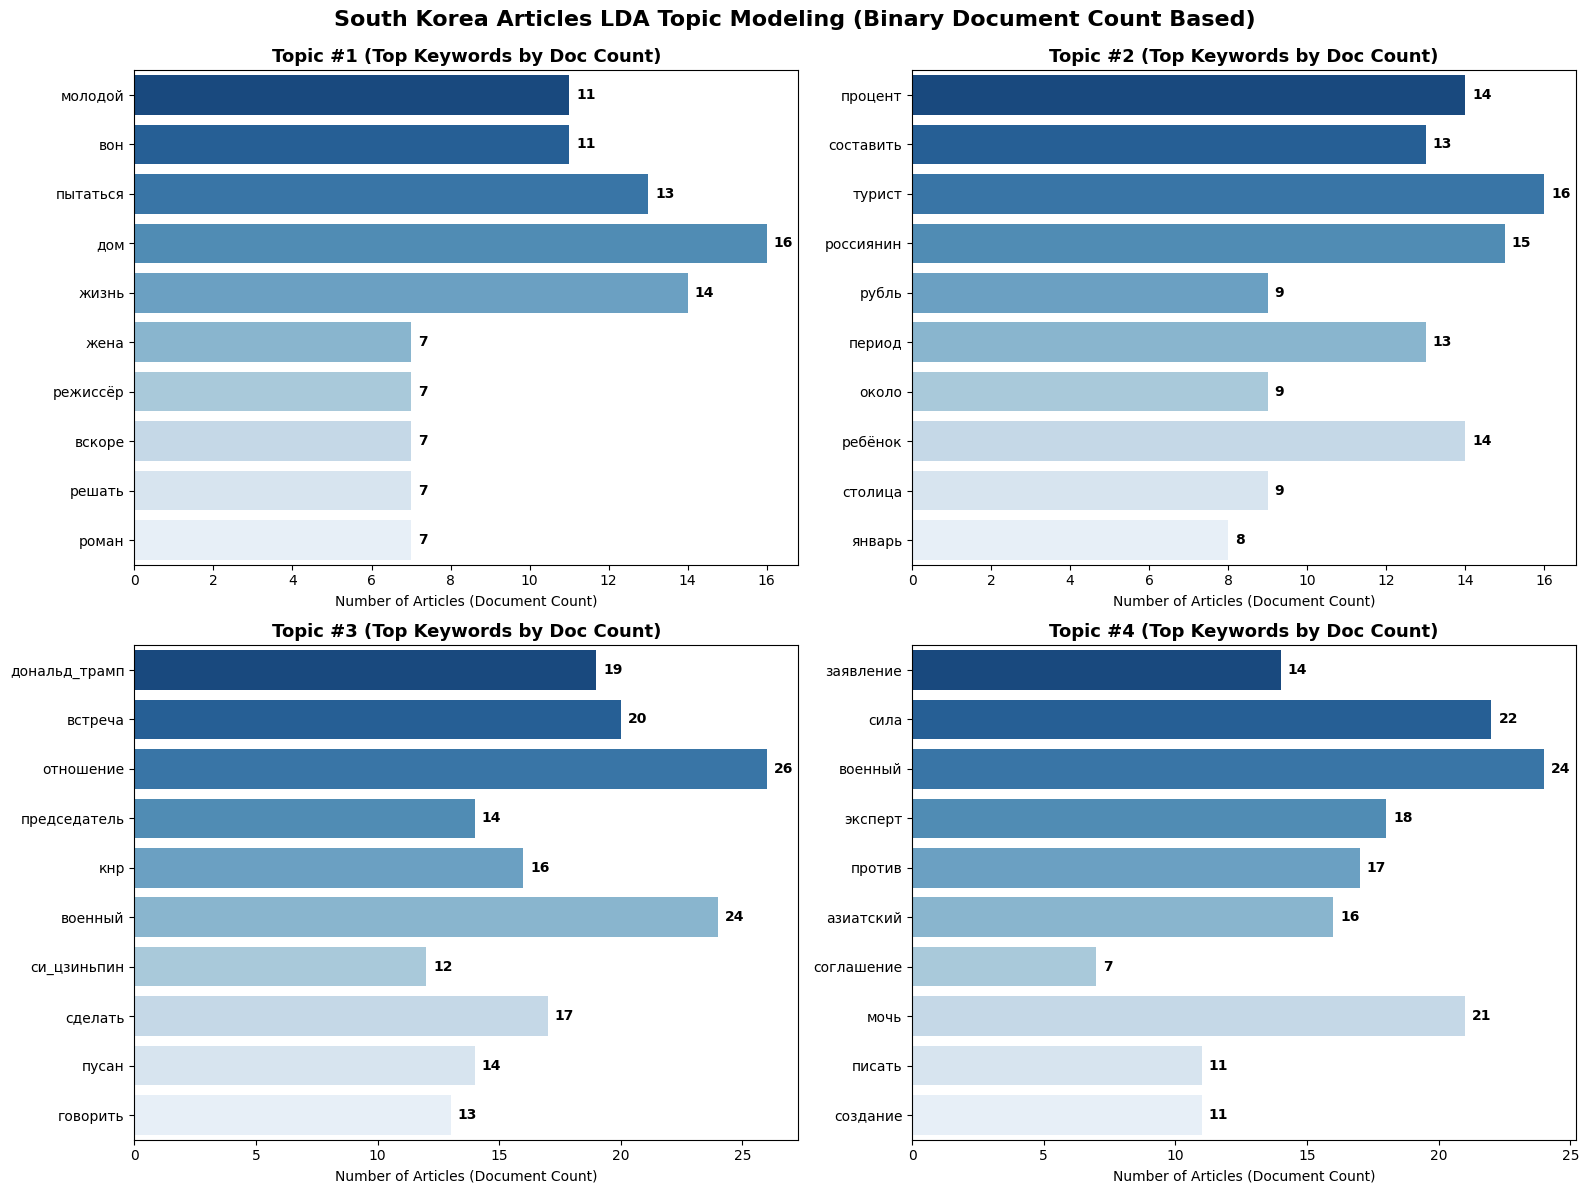

🎉 [남한] 시각화 차트 저장 완료: 'south_korea_topic_analysis_chart.png'
🎉 [남한] 토픽 분석 결과 엑셀 저장 완료: 'lenta_south_korea_topic_results.xlsx'


In [7]:
# ==========================================
# [남한 기사] 문서 출현 기사 수 기준 LDA 토픽 분석 (범용 어휘 제거 반영)
# ==========================================
!pip install pandas openpyxl scikit-learn matplotlib seaborn > /dev/null 2>&1

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

# 1. 전처리된 남한 기사 데이터 불러오기
input_file = 'preprocessed_lenta_south_korea.xlsx'
df_south = pd.read_excel(input_file)

# 2. 토픽 변별력을 떨어뜨리는 범용 동사/부사/접속사 추가 불용어 필터링
extra_south_stops = {
    'получить', 'оставаться', 'остаться', 'видеть', 'делать', 'использовать',
    'считать', 'находиться', 'подчеркнуть', 'назвать', 'соединить',
    'конец', 'именно', 'кроме', 'несколько'
}

df_south['clean_text_refined'] = df_south['clean_text_topic'].apply(
    lambda x: " ".join([w for w in str(x).split() if w not in extra_south_stops])
)

# 3. binary=True 설정을 통해 문서 빈도(출현 기사 수) 반영
vectorizer = CountVectorizer(binary=True, min_df=2)
X_binary = vectorizer.fit_transform(df_south['clean_text_refined'].fillna(''))
feature_names = np.array(vectorizer.get_feature_names_out())

# 4. LDA 토픽 모델링 수행
NUM_TOPICS = 4
lda = LatentDirichletAllocation(n_components=NUM_TOPICS, random_state=42)
lda_output = lda.fit_transform(X_binary)

# 5. 대표 토픽 지정
df_south['dominant_topic'] = np.argmax(lda_output, axis=1) + 1

# 6. 토픽별 시각화 (한글 레이블 제거)
top_n_words = 10
plt.rcParams['font.family'] = 'DejaVu Sans'
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for topic_idx, topic in enumerate(lda.components_):
    top_indices = topic.argsort()[:-top_n_words - 1:-1]
    words = feature_names[top_indices]

    # 실제 출현 기사 수(Document Count) 계산
    word_doc_counts = [X_binary[:, vectorizer.vocabulary_[w]].toarray().sum() for w in words]

    ax = axes[topic_idx]
    sns.barplot(x=word_doc_counts, y=words, ax=ax, palette='Blues_r', orient='h')

    # 막대 옆에 숫자만 깔끔하게 출력
    for p in ax.patches:
        width = p.get_width()
        if width > 0:
            ax.annotate(f'{int(width)}', (width, p.get_y() + p.get_height() / 2.),
                        ha='left', va='center', xytext=(5, 0), textcoords='offset points',
                        fontsize=10, fontweight='bold')

    ax.set_title(f"Topic #{topic_idx + 1} (Top Keywords by Doc Count)", fontsize=13, fontweight='bold')
    ax.set_xlabel('Number of Articles (Document Count)')
    ax.set_ylabel('')

plt.suptitle("South Korea Articles LDA Topic Modeling (Binary Document Count Based)", fontsize=16, y=0.99, fontweight='bold')
plt.tight_layout()

# 7. 임시 컬럼 삭제 후 저장 및 출력
chart_file = 'south_korea_topic_analysis_chart.png'
excel_output = 'lenta_south_korea_topic_results.xlsx'

plt.savefig(chart_file, dpi=300, bbox_inches='tight')
df_south.drop(columns=['clean_text_refined']).to_excel(excel_output, index=False)

plt.show()
print(f"🎉 [남한] 시각화 차트 저장 완료: '{chart_file}'")
print(f"🎉 [남한] 토픽 분석 결과 엑셀 저장 완료: '{excel_output}'")

/tmp/ipykernel_683/4254335963.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=word_doc_counts, y=words, ax=ax, palette='Reds_r', orient='h')
/tmp/ipykernel_683/4254335963.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=word_doc_counts, y=words, ax=ax, palette='Reds_r', orient='h')
/tmp/ipykernel_683/4254335963.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=word_doc_counts, y=words, ax=ax, palette='Reds_r', orient='h')
/tmp/ipykernel_683/4254335963.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is depr

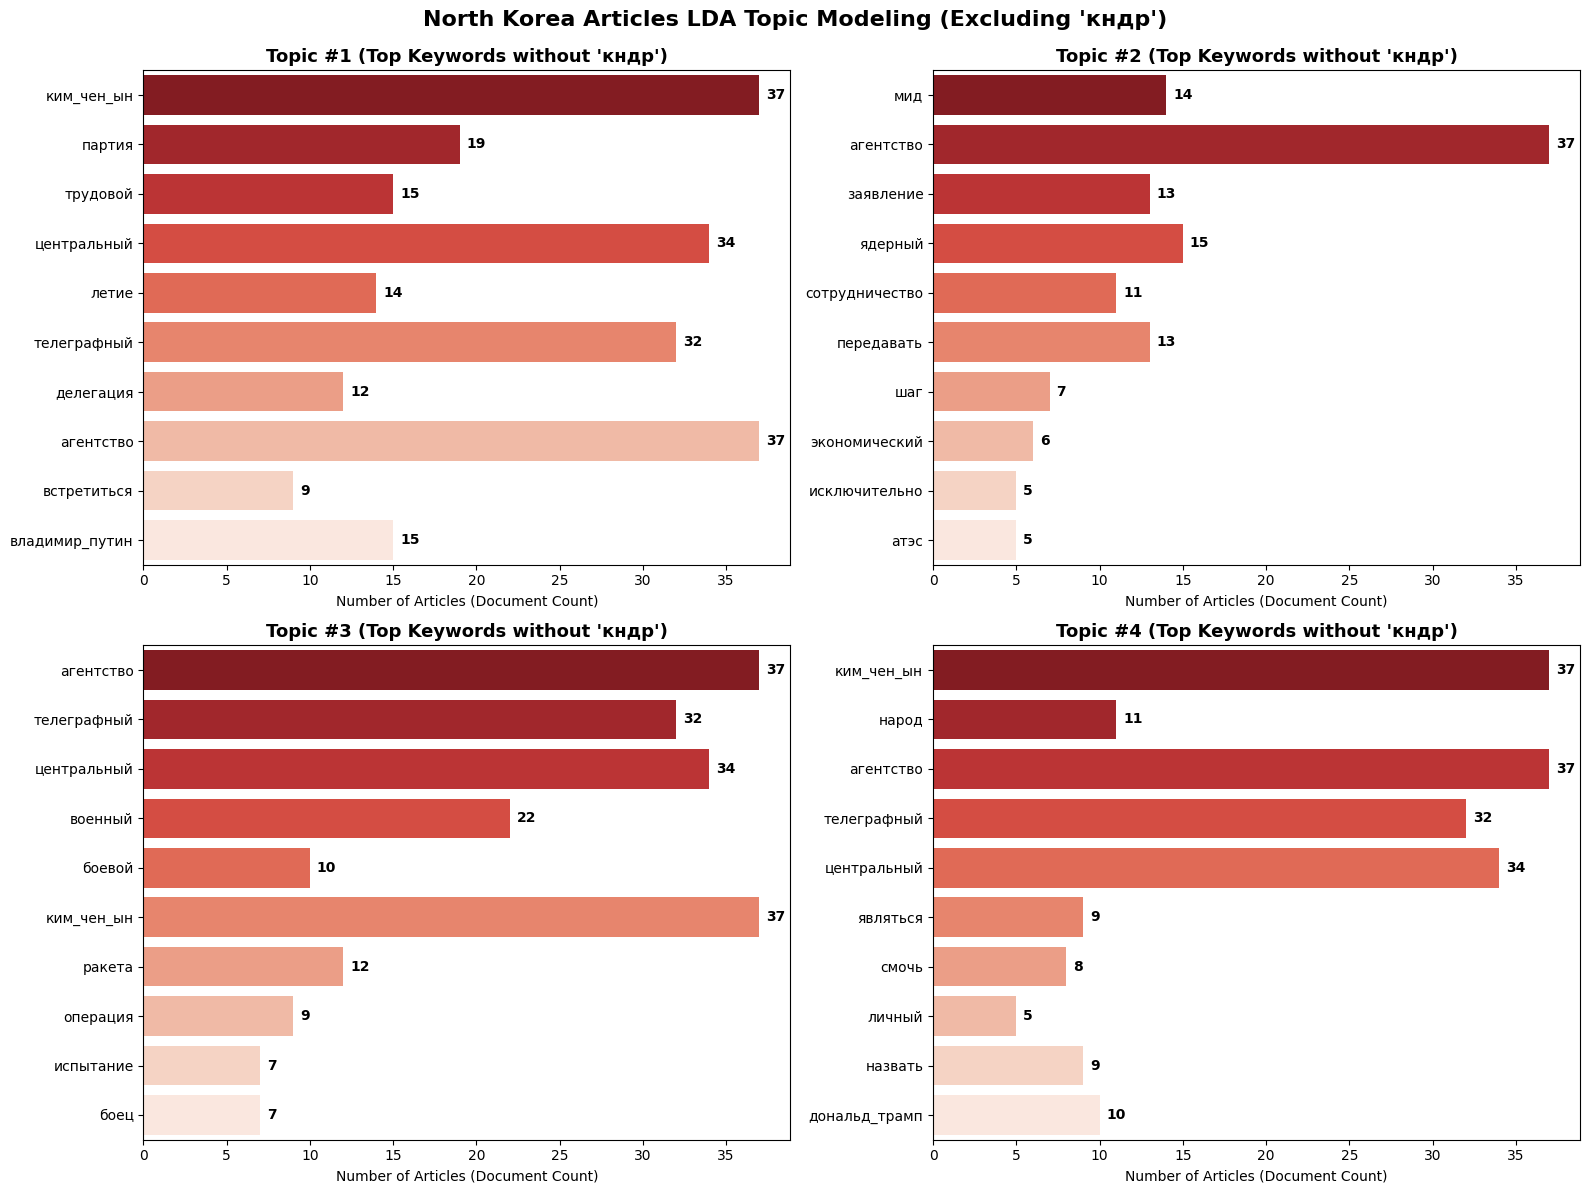

🎉 [북한] 'кндр'가 제외된 시각화 차트 저장 완료: 'north_korea_topic_analysis_chart.png'
🎉 [북한] 토픽 분석 결과 엑셀 저장 완료: 'lenta_north_korea_topic_results.xlsx'


In [6]:
# ==========================================
# [북한 기사] 문서 출현 기사 수 기준 LDA 토픽 분석 ('кндр' 제외 반영)
# ==========================================
!pip install pandas openpyxl scikit-learn matplotlib seaborn > /dev/null 2>&1

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

# 1. 전처리된 북한 기사 데이터 불러오기
input_file = 'preprocessed_lenta_north_korea.xlsx'
df_north = pd.read_excel(input_file)

# 2. 모든 토픽 1위에 도배되던 'кндр'(북한) 단어만 필터링하여 제거
df_north['clean_text_no_kndr'] = df_north['clean_text_topic'].apply(
    lambda x: " ".join([w for w in str(x).split() if w != 'кндр'])
)

# 3. binary=True 설정을 통해 문서 빈도(출현 기사 수) 반영
vectorizer = CountVectorizer(binary=True, min_df=2)
X_binary = vectorizer.fit_transform(df_north['clean_text_no_kndr'].fillna(''))
feature_names = np.array(vectorizer.get_feature_names_out())

# 4. LDA 토픽 모델링 수행
NUM_TOPICS = 4
lda = LatentDirichletAllocation(n_components=NUM_TOPICS, random_state=42)
lda_output = lda.fit_transform(X_binary)

# 5. 대표 토픽 지정
df_north['dominant_topic'] = np.argmax(lda_output, axis=1) + 1

# 6. 토픽별 시각화 (한글 레이블 제거 및 'кндр' 제외 상태 반영)
top_n_words = 10
plt.rcParams['font.family'] = 'DejaVu Sans'
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for topic_idx, topic in enumerate(lda.components_):
    top_indices = topic.argsort()[:-top_n_words - 1:-1]
    words = feature_names[top_indices]

    # 실제 출현 기사 수(Document Count) 계산
    word_doc_counts = [X_binary[:, vectorizer.vocabulary_[w]].toarray().sum() for w in words]

    ax = axes[topic_idx]
    sns.barplot(x=word_doc_counts, y=words, ax=ax, palette='Reds_r', orient='h')

    # 막대 옆에 숫자만 깔끔하게 출력
    for p in ax.patches:
        width = p.get_width()
        if width > 0:
            ax.annotate(f'{int(width)}', (width, p.get_y() + p.get_height() / 2.),
                        ha='left', va='center', xytext=(5, 0), textcoords='offset points',
                        fontsize=10, fontweight='bold')

    ax.set_title(f"Topic #{topic_idx + 1} (Top Keywords without 'кндр')", fontsize=13, fontweight='bold')
    ax.set_xlabel('Number of Articles (Document Count)')
    ax.set_ylabel('')

plt.suptitle("North Korea Articles LDA Topic Modeling (Excluding 'кндр')", fontsize=16, y=0.99, fontweight='bold')
plt.tight_layout()

# 7. 임시 컬럼 삭제 후 저장 및 출력
chart_file = 'north_korea_topic_analysis_chart.png'
excel_output = 'lenta_north_korea_topic_results.xlsx'

plt.savefig(chart_file, dpi=300, bbox_inches='tight')
df_north.drop(columns=['clean_text_no_kndr']).to_excel(excel_output, index=False)

plt.show()
print(f"🎉 [북한] 'кндр'가 제외된 시각화 차트 저장 완료: '{chart_file}'")
print(f"🎉 [북한] 토픽 분석 결과 엑셀 저장 완료: '{excel_output}'")

📁 남한 기사 데이터 불러오기 완료: 총 107건
⏳ RuBERT 감성 분석 AI 모델 로딩 중...


config.json:   0%|          | 0.00/943 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/499 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.40M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  711MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

⏳ 남한 기사 감성 분석 실행 중...


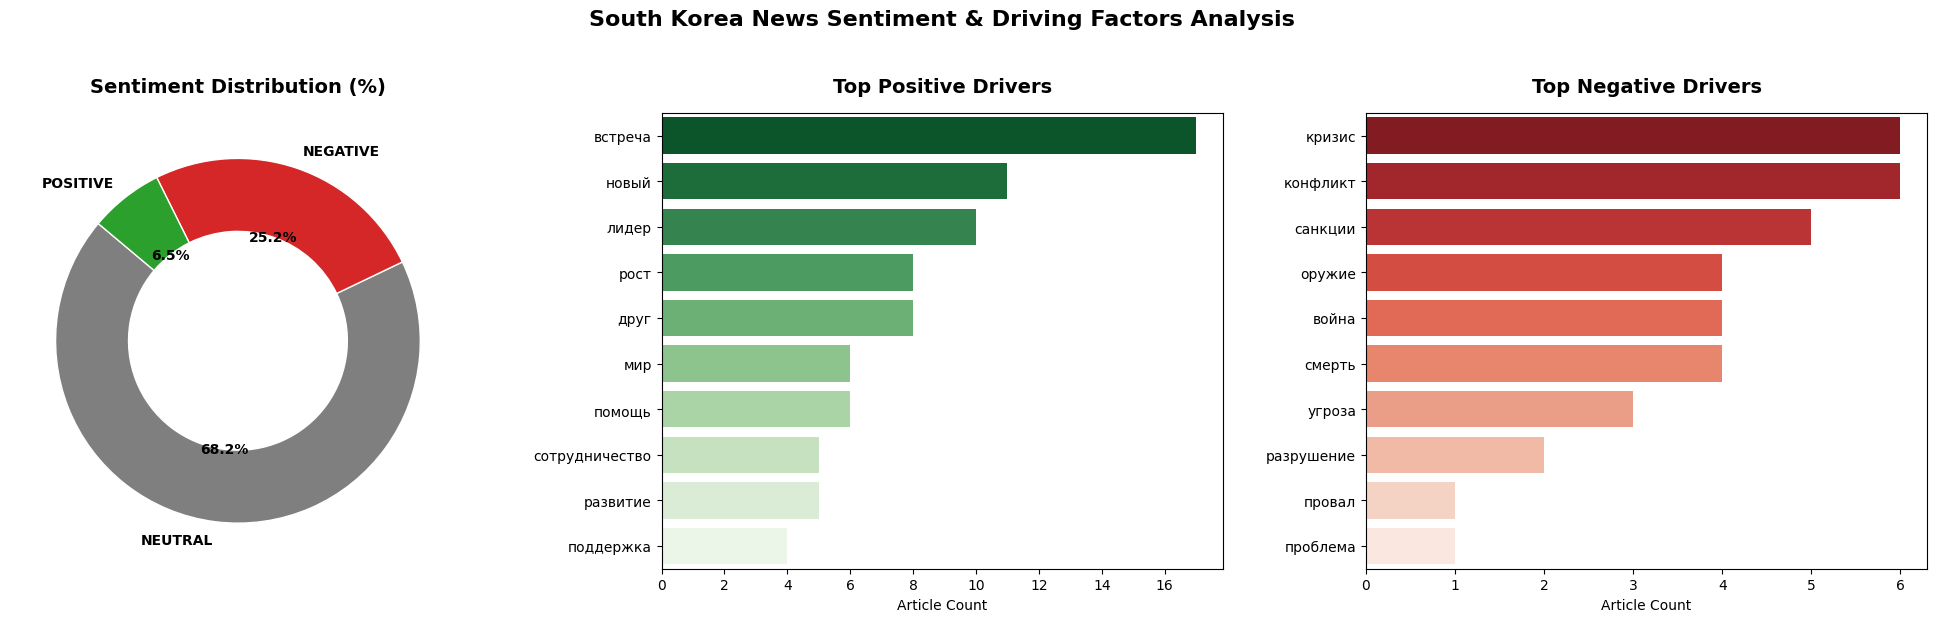

🎉 [남한] 시각화 저장 완료: 'south_korea_sentiment_ratio_and_reasons.png'
🎉 [남한] 엑셀 결과 저장 완료: 'lenta_south_korea_sentiment_results.xlsx'


In [8]:
# ==========================================
# [남한 기사] RuBERT 감성 분석 (비율 % + 원인 단어 통합 시각화)
# ==========================================
!pip install pandas openpyxl transformers torch matplotlib seaborn > /dev/null 2>&1

import re
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# 1. 파일 불러오기
input_file = 'lenta_south_korea.xlsx'
df = pd.read_excel(input_file)
print(f"📁 남한 기사 데이터 불러오기 완료: 총 {len(df)}건")

# 2. 공개 허깅페이스 RuBERT 감성 모델 로드 (토큰/로그인 불필요)
MODEL_NAME = 'blanchefort/rubert-base-cased-sentiment'
print("⏳ RuBERT 감성 분석 AI 모델 로딩 중...")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME)
model.eval()

# 모델 고유 라벨 자동 매핑 (대문자로 통일: NEUTRAL, POSITIVE, NEGATIVE)
id2label = {idx: label.upper() for idx, label in model.config.id2label.items()}

# 주요 감성 어휘 사전 (원인 추출용)
pos_lexicon = {'успех', 'соглашение', 'партнерство', 'развитие', 'сотрудничество', 'рост', 'победа', 'поддержка', 'популярность', 'новый', 'друг', 'встреча', 'договор', 'создание', 'лидер', 'прогресс', 'хороший', 'высокий', 'надежда', 'помощь', 'выгодно', 'мир', 'прорыв', 'достижение', 'укрепление', 'стабильность', 'безопасность', 'инвестиции'}
neg_lexicon = {'война', 'отказ', 'угроза', 'конфликт', 'провал', 'удар', 'кризис', 'санкции', 'оружие', 'смерть', 'потеря', 'риск', 'напряжение', 'атака', 'отклонить', 'погибнуть', 'проблема', 'катастрофа', 'опасность', 'ухудшение', 'обвинение', 'жертва', 'разрушение', 'задержание', 'арест', 'взрыв', 'противостояние', 'критика', 'испытание'}

# 3. 감성 분석 및 원인 추출 함수
def analyze_sentiment(text):
    if not isinstance(text, str) or not text.strip():
        return 'NEUTRAL', 0.5, '전반적 문맥/어조', '전반적 문맥/어조'

    clean_text = re.sub(r'http\S+|www\.\S+', '', text)
    clean_text = re.sub(r'[^\w\s\.\,\!\?]', ' ', clean_text)
    clean_text = re.sub(r'\s+', ' ', clean_text).strip()

    inputs = tokenizer(clean_text[:512], return_tensors='pt', truncation=True, max_length=512)
    with torch.no_grad():
        outputs = model(**inputs)
        probs = torch.softmax(outputs.logits, dim=1).numpy()[0]

    pred_idx = np.argmax(probs)
    sentiment = id2label[pred_idx]
    confidence = float(probs[pred_idx])

    words = set(re.findall(r'[а-яА-ЯёЁ]+', clean_text.lower()))
    found_pos = words.intersection(pos_lexicon)
    found_neg = words.intersection(neg_lexicon)

    pos_reasons = ", ".join(list(found_pos)[:5]) if found_pos else "전반적 문맥/어조"
    neg_reasons = ", ".join(list(found_neg)[:5]) if found_neg else "전반적 문맥/어조"

    return sentiment, confidence, pos_reasons, neg_reasons

print("⏳ 남한 기사 감성 분석 실행 중...")
results = [analyze_sentiment(str(row['제목']) + ". " + str(row['본문'])) for _, row in df.iterrows()]

df['sentiment'] = [r[0] for r in results]
df['sentiment_confidence'] = [round(r[1], 4) for r in results]
df['positive_drivers'] = [r[2] for r in results]
df['negative_drivers'] = [r[3] for r in results]

# 4. 3분할 통합 시각화 (퍼센트 도넛 차트 + 긍정 원인 + 부정 원인)
plt.rcParams['font.family'] = 'DejaVu Sans'
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# (1) 왼쪽: 감성 비율 도넛 차트
sentiment_counts = df['sentiment'].value_counts()
colors_map = {'POSITIVE': '#2ca02c', 'NEUTRAL': '#7f7f7f', 'NEGATIVE': '#d62728'}
chart_colors = [colors_map.get(label, '#1f77b4') for label in sentiment_counts.index]

axes[0].pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=chart_colors,
    textprops=dict(color="black", fontweight='bold'),
    wedgeprops=dict(width=0.4, edgecolor='white')
)
axes[0].set_title('Sentiment Distribution (%)', fontsize=14, fontweight='bold', pad=15)

# (2) 중앙: 긍정 원인 단어 TOP 10
all_pos_words = [w.strip() for text in df['positive_drivers'] for w in text.split(',') if w.strip() and w != "전반적 문맥/어조"]
pos_counts = Counter(all_pos_words).most_common(10)

if pos_counts:
    words, counts = zip(*pos_counts)
    sns.barplot(x=list(counts), y=list(words), ax=axes[1], palette='Greens_r', orient='h', hue=list(words), legend=False)
    axes[1].set_title('Top Positive Drivers', fontsize=14, fontweight='bold', pad=15)
    axes[1].set_xlabel('Article Count')

# (3) 오른쪽: 부정 원인 단어 TOP 10
all_neg_words = [w.strip() for text in df['negative_drivers'] for w in text.split(',') if w.strip() and w != "전반적 문맥/어조"]
neg_counts = Counter(all_neg_words).most_common(10)

if neg_counts:
    words, counts = zip(*neg_counts)
    sns.barplot(x=list(counts), y=list(words), ax=axes[2], palette='Reds_r', orient='h', hue=list(words), legend=False)
    axes[2].set_title('Top Negative Drivers', fontsize=14, fontweight='bold', pad=15)
    axes[2].set_xlabel('Article Count')
else:
    axes[2].text(0.5, 0.5, 'No Negative Drivers Found', ha='center', va='center', fontsize=12)

plt.suptitle('South Korea News Sentiment & Driving Factors Analysis', fontsize=16, y=1.03, fontweight='bold')
plt.tight_layout()

# 5. 파일 저장
chart_file = 'south_korea_sentiment_ratio_and_reasons.png'
excel_file = 'lenta_south_korea_sentiment_results.xlsx'

plt.savefig(chart_file, dpi=300, bbox_inches='tight')
df.to_excel(excel_file, index=False)

plt.show()
print(f"🎉 [남한] 시각화 저장 완료: '{chart_file}'")
print(f"🎉 [남한] 엑셀 결과 저장 완료: '{excel_file}'")

📁 북한 기사 데이터 불러오기 완료: 총 77건
⏳ RuBERT 감성 분석 AI 모델 로딩 중...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

⏳ 북한 기사 감성 분석 실행 중...


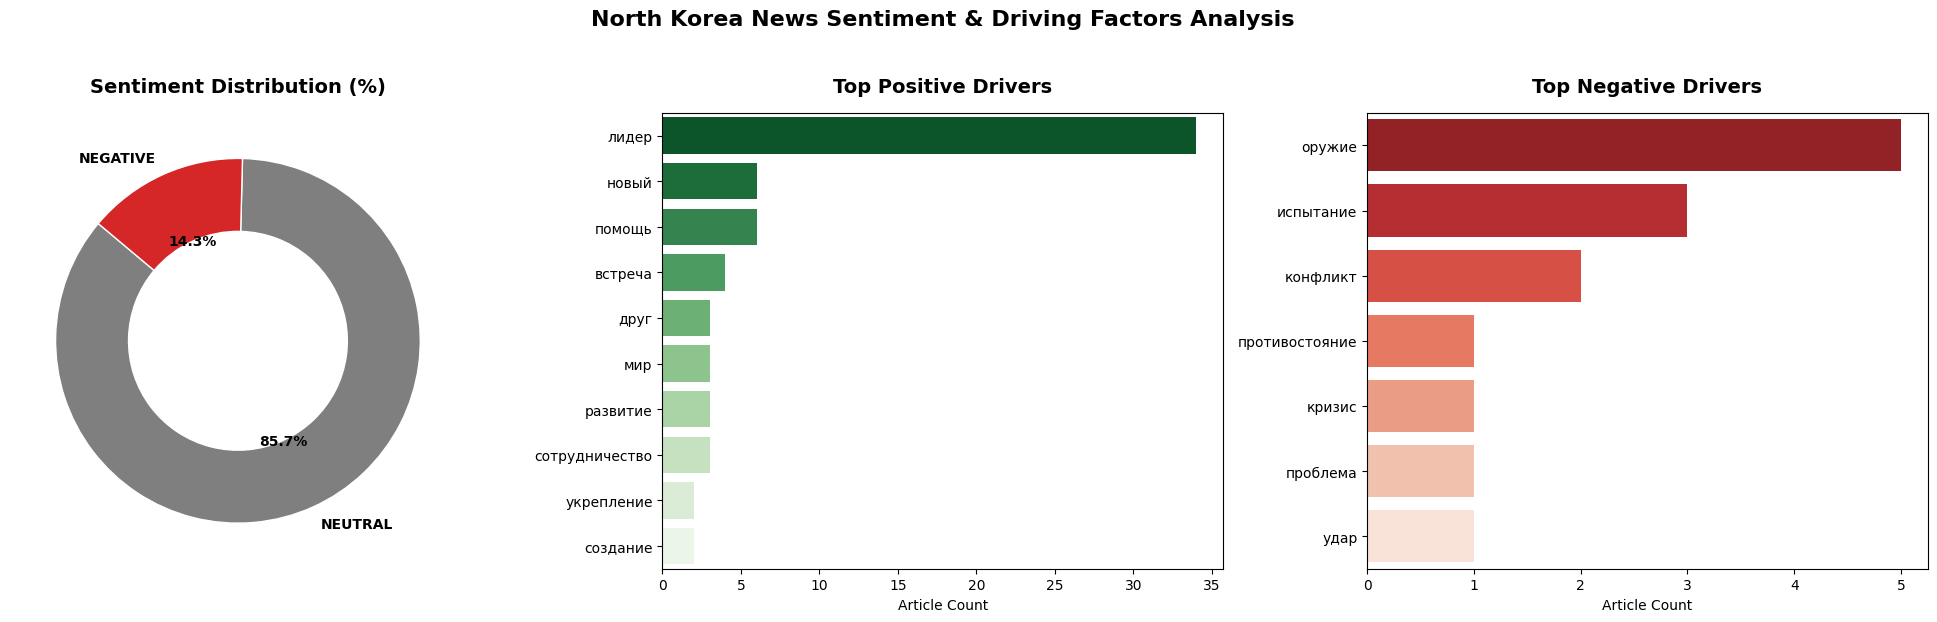

🎉 [북한] 시각화 저장 완료: 'north_korea_sentiment_ratio_and_reasons.png'
🎉 [북한] 엑셀 결과 저장 완료: 'lenta_north_korea_sentiment_results.xlsx'


In [9]:
# ==========================================
# [북한 기사] RuBERT 감성 분석 (비율 % + 원인 단어 통합 시각화)
# ==========================================
!pip install pandas openpyxl transformers torch matplotlib seaborn > /dev/null 2>&1

import re
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# 1. 파일 불러오기
input_file = 'lenta_north_korea.xlsx'
df = pd.read_excel(input_file)
print(f"📁 북한 기사 데이터 불러오기 완료: 총 {len(df)}건")

# 2. 공개 허깅페이스 RuBERT 감성 모델 로드 (토큰/로그인 불필요)
MODEL_NAME = 'blanchefort/rubert-base-cased-sentiment'
print("⏳ RuBERT 감성 분석 AI 모델 로딩 중...")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME)
model.eval()

id2label = {idx: label.upper() for idx, label in model.config.id2label.items()}

pos_lexicon = {'успех', 'соглашение', 'партнерство', 'развитие', 'сотрудничество', 'рост', 'победа', 'поддержка', 'популярность', 'новый', 'друг', 'встреча', 'договор', 'создание', 'лидер', 'прогресс', 'хороший', 'высокий', 'надежда', 'помощь', 'выгодно', 'мир', 'прорыв', 'достижение', 'укрепление', 'стабильность', 'безопасность', 'инвестиции'}
neg_lexicon = {'война', 'отказ', 'угроза', 'конфликт', 'провал', 'удар', 'кризис', 'санкции', 'оружие', 'смерть', 'потеря', 'риск', 'напряжение', 'атака', 'отклонить', 'погибнуть', 'проблема', 'катастрофа', 'опасность', 'ухудшение', 'обвинение', 'жертва', 'разрушение', 'задержание', 'арест', 'взрыв', 'противостояние', 'критика', 'испытание'}

# 3. 감성 분석 및 원인 추출 함수
def analyze_sentiment(text):
    if not isinstance(text, str) or not text.strip():
        return 'NEUTRAL', 0.5, '전반적 문맥/어조', '전반적 문맥/어조'

    clean_text = re.sub(r'http\S+|www\.\S+', '', text)
    clean_text = re.sub(r'[^\w\s\.\,\!\?]', ' ', clean_text)
    clean_text = re.sub(r'\s+', ' ', clean_text).strip()

    inputs = tokenizer(clean_text[:512], return_tensors='pt', truncation=True, max_length=512)
    with torch.no_grad():
        outputs = model(**inputs)
        probs = torch.softmax(outputs.logits, dim=1).numpy()[0]

    pred_idx = np.argmax(probs)
    sentiment = id2label[pred_idx]
    confidence = float(probs[pred_idx])

    words = set(re.findall(r'[а-яА-ЯёЁ]+', clean_text.lower()))
    found_pos = words.intersection(pos_lexicon)
    found_neg = words.intersection(neg_lexicon)

    pos_reasons = ", ".join(list(found_pos)[:5]) if found_pos else "전반적 문맥/어조"
    neg_reasons = ", ".join(list(found_neg)[:5]) if found_neg else "전반적 문맥/어조"

    return sentiment, confidence, pos_reasons, neg_reasons

print("⏳ 북한 기사 감성 분석 실행 중...")
results = [analyze_sentiment(str(row['제목']) + ". " + str(row['본문'])) for _, row in df.iterrows()]

df['sentiment'] = [r[0] for r in results]
df['sentiment_confidence'] = [round(r[1], 4) for r in results]
df['positive_drivers'] = [r[2] for r in results]
df['negative_drivers'] = [r[3] for r in results]

# 4. 3분할 통합 시각화 (퍼센트 도넛 차트 + 긍정 원인 + 부정 원인)
plt.rcParams['font.family'] = 'DejaVu Sans'
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# (1) 왼쪽: 감성 비율 도넛 차트
sentiment_counts = df['sentiment'].value_counts()
colors_map = {'POSITIVE': '#2ca02c', 'NEUTRAL': '#7f7f7f', 'NEGATIVE': '#d62728'}
chart_colors = [colors_map.get(label, '#1f77b4') for label in sentiment_counts.index]

axes[0].pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=chart_colors,
    textprops=dict(color="black", fontweight='bold'),
    wedgeprops=dict(width=0.4, edgecolor='white')
)
axes[0].set_title('Sentiment Distribution (%)', fontsize=14, fontweight='bold', pad=15)

# (2) 중앙: 긍정 원인 단어 TOP 10
all_pos_words = [w.strip() for text in df['positive_drivers'] for w in text.split(',') if w.strip() and w != "전반적 문맥/어조"]
pos_counts = Counter(all_pos_words).most_common(10)

if pos_counts:
    words, counts = zip(*pos_counts)
    sns.barplot(x=list(counts), y=list(words), ax=axes[1], palette='Greens_r', orient='h', hue=list(words), legend=False)
    axes[1].set_title('Top Positive Drivers', fontsize=14, fontweight='bold', pad=15)
    axes[1].set_xlabel('Article Count')

# (3) 오른쪽: 부정 원인 단어 TOP 10
all_neg_words = [w.strip() for text in df['negative_drivers'] for w in text.split(',') if w.strip() and w != "전반적 문맥/어조"]
neg_counts = Counter(all_neg_words).most_common(10)

if neg_counts:
    words, counts = zip(*neg_counts)
    sns.barplot(x=list(counts), y=list(words), ax=axes[2], palette='Reds_r', orient='h', hue=list(words), legend=False)
    axes[2].set_title('Top Negative Drivers', fontsize=14, fontweight='bold', pad=15)
    axes[2].set_xlabel('Article Count')
else:
    axes[2].text(0.5, 0.5, 'No Negative Drivers Found', ha='center', va='center', fontsize=12)

plt.suptitle('North Korea News Sentiment & Driving Factors Analysis', fontsize=16, y=1.03, fontweight='bold')
plt.tight_layout()

# 5. 파일 저장
chart_file = 'north_korea_sentiment_ratio_and_reasons.png'
excel_file = 'lenta_north_korea_sentiment_results.xlsx'

plt.savefig(chart_file, dpi=300, bbox_inches='tight')
df.to_excel(excel_file, index=False)

plt.show()
print(f"🎉 [북한] 시각화 저장 완료: '{chart_file}'")
print(f"🎉 [북한] 엑셀 결과 저장 완료: '{excel_file}'")